# Probability & Information Theory for Deep Learning

### A worked notebook based on Chapter 3 lecture slides from *Deep Learning*
**Ian Goodfellow, Yoshua Bengio, Aaron Courville**

This notebook turns the lecture slides into a learn-by-doing sequence:

1. **Understand** the definition and intuition.
2. **Derive** important equations.
3. **Implement** the ideas with NumPy.
4. **Visualize** probability distributions and transformations.
5. **Check yourself** with exercises.

The notebook covers PMFs/PDFs, marginal and conditional probability, the chain rule, independence, expectation and covariance, common distributions, sigmoid and softplus, Bayes' rule, change of variables, information theory, and graphical models.

## Learning map

The main progression is:

- Probability mass functions and probability density functions
- Marginal and conditional probability
- Chain rule
- Independence and conditional independence
- Expectation, variance, covariance, covariance matrices
- Bernoulli and multinoulli distributions
- Gaussian and multivariate Gaussian distributions
- Exponential and Laplace distributions
- Dirac delta and empirical distributions
- Mixture distributions
- Logistic sigmoid and softplus
- Bayes' rule
- Change of variables
- Self-information
- Shannon entropy
- KL divergence
- Directed graphical models
- Undirected graphical models

The central theme is that deep learning repeatedly uses probability distributions to represent uncertainty, expectations to define objectives, transformations to construct models, and information-theoretic quantities to compare distributions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

print("NumPy:", np.__version__)

NumPy: 2.5.3


# 1. Probability Mass Functions

For a discrete random variable, a probability mass function assigns a probability to every possible state.

A valid PMF satisfies

$$
P(x) \ge 0
$$

and

$$
\sum_x P(x) = 1.
$$

A joint distribution such as $P(x,y)$ describes the probability of simultaneous assignments of $x$ and $y$.

In [2]:
states = np.array(["A", "B", "C", "D"])
p = np.array([0.10, 0.20, 0.50, 0.20])

assert np.all(p >= 0)
assert np.isclose(p.sum(), 1.0)

print("states:", states)
print("probabilities:", p)
print("P(C):", p[2])

states: ['A' 'B' 'C' 'D']
probabilities: [0.1 0.2 0.5 0.2]
P(C): 0.5


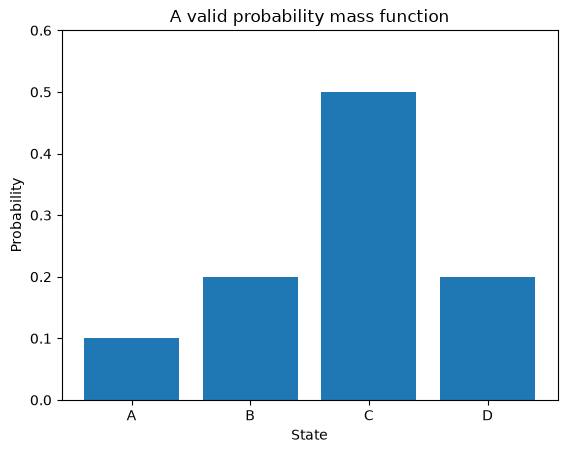

In [3]:
plt.bar(states, p)
plt.xlabel("State")
plt.ylabel("Probability")
plt.title("A valid probability mass function")
plt.ylim(0, 0.6)
plt.show()

### Uniform distribution

If a discrete variable has $k$ possible states and every state is equally likely,

$$
P(x=x_i) = \frac{1}{k}.
$$

The normalization is

$$
\sum_{i=1}^{k}\frac{1}{k}=1.
$$

In [4]:
k = 6
uniform_p = np.ones(k) / k

print(uniform_p)
print("sum =", uniform_p.sum())

[0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]
sum = 0.9999999999999999


### Exercise 1

Create a PMF over five states with probabilities proportional to

$$
1,\quad 2,\quad 3,\quad 2,\quad 2.
$$

Normalize it and verify that the probabilities sum to one.

In [5]:
weights = np.array([1, 2, 3, 2, 2], dtype=float)
p_ex1 = weights / weights.sum()

print(p_ex1)
assert np.isclose(p_ex1.sum(), 1)

[0.1 0.2 0.3 0.2 0.2]


# 2. Probability Density Functions

For a continuous random variable, probability is represented by a **probability density function** $p(x)$.

A PDF satisfies

$$
p(x) \ge 0
$$

and

$$
\int_{-\infty}^{\infty}p(x)\,dx = 1.
$$

Probability over an interval is obtained by integrating:

$$
P(a \le X \le b)
=
\int_a^b p(x)\,dx.
$$

Unlike a PMF, a PDF can have a value greater than $1$. What must equal $1$ is its total integral.

### Continuous uniform distribution

For $x\in[a,b]$,

$$
u(x;a,b)
=
\frac{1}{b-a},
$$

and the density is zero outside $[a,b]$.

We write

$$
X\sim U(a,b).
$$

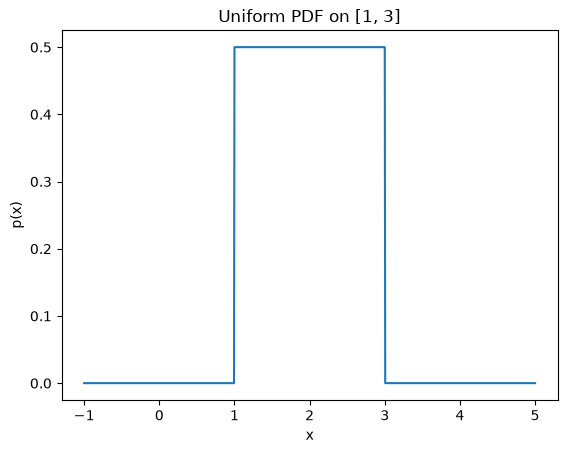

Approximate integral: 1.0030030030030028


In [6]:
def uniform_pdf(x, a, b):
    x = np.asarray(x)
    return np.where((x >= a) & (x <= b), 1.0 / (b - a), 0.0)

x = np.linspace(-1, 5, 1000)
pdf = uniform_pdf(x, 1, 3)

plt.plot(x, pdf)
plt.xlabel("x")
plt.ylabel("p(x)")
plt.title("Uniform PDF on [1, 3]")
plt.show()

area = np.trapezoid(pdf, x)
print("Approximate integral:", area)

# 3. Marginal Probability

Suppose we have a joint distribution $P(x,y)$ but only care about $x$.

For discrete variables, we **sum out** $y$:

$$
P(x)
=
\sum_y P(x,y).
$$

For continuous variables, we integrate:

$$
p(x)
=
\int p(x,y)\,dy.
$$

This is marginalization.

In [7]:
joint = np.array([
    [0.10, 0.20, 0.10],
    [0.15, 0.25, 0.20]
])

print("Joint distribution:\n", joint)
print("Total:", joint.sum())

px = joint.sum(axis=1)
py = joint.sum(axis=0)

print("P(x):", px)
print("P(y):", py)

assert np.isclose(px.sum(), 1)
assert np.isclose(py.sum(), 1)

Joint distribution:
 [[0.1  0.2  0.1 ]
 [0.15 0.25 0.2 ]]
Total: 1.0
P(x): [0.4 0.6]
P(y): [0.25 0.45 0.3 ]


The key intuition is simple:

> To forget a variable, add or integrate over all of its possible values.

For a probability table, marginalization is therefore a row/column summation operation.

# 4. Conditional Probability

Conditional probability asks:

> What is the probability of $y$, given that we know $x$?

The definition is

$$
P(y\mid x)
=
\frac{P(y,x)}{P(x)},
$$

provided that $P(x)>0$.

A useful memory aid is

$$
\boxed{
\text{conditional}
=
\frac{\text{joint}}{\text{conditioning marginal}}
}.
$$

In [8]:
conditional_y_given_x = joint / px[:, None]

print("Rows are x; columns are y")
print(conditional_y_given_x)
print("Each row sums to:", conditional_y_given_x.sum(axis=1))

assert np.allclose(conditional_y_given_x.sum(axis=1), 1)

Rows are x; columns are y
[[0.25   0.5    0.25  ]
 [0.25   0.4167 0.3333]]
Each row sums to: [1. 1.]


### Conditional probability is not intervention

Conditional probability and causal intervention are different concepts.

For example, observing that someone speaks German and asking about their country of origin is a conditional question. Teaching someone German and asking whether their country of origin changes is an intervention question.

This distinction becomes important in causal modeling.

# 5. Chain Rule of Probability

The joint distribution of many variables can be decomposed into conditional distributions.

For three variables,

$$
P(a,b,c)
=
P(a\mid b,c)\,P(b\mid c)\,P(c).
$$

More generally,

$$
P(x^{(1)},\ldots,x^{(n)})
=
P(x^{(1)})
\prod_{i=2}^{n}
P\left(
x^{(i)}
\mid
x^{(1)},\ldots,x^{(i-1)}
\right).
$$

The chain rule follows directly from repeatedly applying the definition of conditional probability.

In [9]:
P_c = {0: 0.6, 1: 0.4}

P_b_given_c = {
    (0, 0): 0.7, (1, 0): 0.3,
    (0, 1): 0.2, (1, 1): 0.8
}

P_a_given_bc = {
    (0, 0, 0): 0.9, (1, 0, 0): 0.1,
    (0, 1, 0): 0.4, (1, 1, 0): 0.6,
    (0, 0, 1): 0.3, (1, 0, 1): 0.7,
    (0, 1, 1): 0.8, (1, 1, 1): 0.2,
}

joint_sum = 0

for a in [0, 1]:
    for b in [0, 1]:
        for c in [0, 1]:
            joint_sum += (
                P_a_given_bc[(a, b, c)]
                * P_b_given_c[(b, c)]
                * P_c[c]
            )

print("Sum over all joint states:", joint_sum)
assert np.isclose(joint_sum, 1)

Sum over all joint states: 1.0


# 6. Independence and Conditional Independence

Two variables $x$ and $y$ are independent when

$$
P(x,y)
=
P(x)P(y).
$$

Intuitively, learning one variable does not change the distribution of the other.

Conditional independence given $z$ means

$$
P(x,y\mid z)
=
P(x\mid z)P(y\mid z).
$$

Two variables can therefore be dependent marginally but independent after conditioning on another variable.

In [10]:
px = np.array([0.3, 0.7])
py = np.array([0.2, 0.5, 0.3])

joint_independent = np.outer(px, py)

print(joint_independent)
assert np.allclose(joint_independent, np.outer(px, py))

[[0.06 0.15 0.09]
 [0.14 0.35 0.21]]


### Important warning

Independence is stronger than zero covariance.

If $X$ and $Y$ are independent and the relevant moments exist, then

$$
\operatorname{Cov}(X,Y)=0.
$$

But the converse is not generally true: zero covariance only rules out linear dependence. Nonlinear dependence can remain.

# 7. Expectation

The expectation of $f(X)$ is its average value under the distribution of $X$.

For a discrete variable,

$$
\mathbb{E}_{X\sim P}[f(X)]
=
\sum_x P(x)f(x).
$$

For a continuous variable,

$$
\mathbb{E}_{X\sim p}[f(X)]
=
\int p(x)f(x)\,dx.
$$

Expectation is linear:

$$
\mathbb{E}[\alpha f(X)+\beta g(X)]
=
\alpha\mathbb{E}[f(X)]
+
\beta\mathbb{E}[g(X)].
$$

In [11]:
values = np.array([0., 1., 2., 3.])
probs = np.array([0.1, 0.2, 0.4, 0.3])

E_x = np.sum(values * probs)
E_x2 = np.sum(values**2 * probs)

print("E[X]   =", E_x)
print("E[X^2] =", E_x2)

E[X]   = 1.9
E[X^2] = 4.5


# 8. Variance, Standard Deviation, and Covariance

Variance measures the spread of a random quantity:

$$
\operatorname{Var}(f(X))
=
\mathbb{E}
\left[
\left(
f(X)-\mathbb{E}[f(X)]
\right)^2
\right].
$$

Standard deviation is

$$
\sigma
=
\sqrt{\operatorname{Var}(X)}.
$$

An extremely useful identity is

$$
\operatorname{Var}(X)
=
\mathbb{E}[X^2]
-
\mathbb{E}[X]^2.
$$

Covariance is

$$
\operatorname{Cov}(X,Y)
=
\mathbb{E}
\left[
(X-\mathbb{E}[X])
(Y-\mathbb{E}[Y])
\right].
$$

In [12]:
x = np.array([0., 1., 2., 3.])
p = np.array([0.1, 0.2, 0.4, 0.3])

mu = np.sum(p * x)
var = np.sum(p * (x - mu)**2)
var_alt = np.sum(p * x**2) - mu**2
std = np.sqrt(var)

print("mean:", mu)
print("variance:", var)
print("variance via E[X^2]-E[X]^2:", var_alt)
print("standard deviation:", std)

assert np.isclose(var, var_alt)

mean: 1.9
variance: 0.8899999999999999
variance via E[X^2]-E[X]^2: 0.8900000000000001
standard deviation: 0.9433981132056604


In [13]:
n = 200_000
samples_x = rng.normal(size=n)
samples_y = 0.7 * samples_x + rng.normal(scale=0.8, size=n)

cov = np.mean(
    (samples_x - samples_x.mean())
    * (samples_y - samples_y.mean())
)

print("Estimated covariance:", cov)

Estimated covariance: 0.701598474889301


# 9. Covariance Matrices

For a random vector $X\in\mathbb{R}^n$, the covariance matrix contains every pairwise covariance:

$$
\operatorname{Cov}(X)_{ij}
=
\operatorname{Cov}(X_i,X_j).
$$

The diagonal entries are variances:

$$
\operatorname{Cov}(X_i,X_i)
=
\operatorname{Var}(X_i).
$$

In [14]:
X = np.column_stack([samples_x, samples_y])
cov_matrix = np.cov(X, rowvar=False, bias=True)

print(cov_matrix)
print("Diagonal:", np.diag(cov_matrix))

[[1.0055 0.7016]
 [0.7016 1.1276]]
Diagonal: [1.0055 1.1276]


# 10. Bernoulli Distribution

The Bernoulli distribution models one binary random variable.

With parameter $\phi\in[0,1]$,

$$
P(X=1)=\phi,
\qquad
P(X=0)=1-\phi.
$$

A compact expression is

$$
P(X=x)
=
\phi^x(1-\phi)^{1-x},
\qquad
x\in\{0,1\}.
$$

Its mean and variance are

$$
\mathbb{E}[X]=\phi
$$

and

$$
\operatorname{Var}(X)=\phi(1-\phi).
$$

In [15]:
def bernoulli_pmf(x, phi):
    x = np.asarray(x)
    return phi**x * (1 - phi)**(1 - x)

phi = 0.7
x = np.array([0, 1])

print(bernoulli_pmf(x, phi))
print("mean:", phi)
print("variance:", phi * (1 - phi))

[0.3 0.7]
mean: 0.7
variance: 0.21000000000000002


# 11. Multinoulli / Categorical Distribution

The multinoulli, commonly called the categorical distribution, models a discrete variable with $k$ possible states.

Its probabilities satisfy

$$
p_i\ge0,
\qquad
\sum_{i=1}^{k}p_i=1.
$$

Unlike a Bernoulli variable, the category labels generally do not have meaningful numerical ordering.

In [16]:
categories = ["cat", "dog", "bird", "fish"]
p_cat = np.array([0.15, 0.45, 0.25, 0.15])

assert np.isclose(p_cat.sum(), 1)

print(dict(zip(categories, p_cat)))

samples = rng.choice(categories, size=20, p=p_cat)
print("samples:", samples)

{'cat': np.float64(0.15), 'dog': np.float64(0.45), 'bird': np.float64(0.25), 'fish': np.float64(0.15)}
samples: ['dog' 'fish' 'dog' 'dog' 'cat' 'dog' 'cat' 'bird' 'bird' 'cat' 'bird'
 'dog' 'bird' 'cat' 'dog' 'bird' 'bird' 'dog' 'dog' 'dog']


# 12. Gaussian Distribution

The one-dimensional Gaussian distribution is

$$
\mathcal{N}(x;\mu,\sigma^2)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp
\left(
-\frac{(x-\mu)^2}{2\sigma^2}
\right).
$$

Here:

- $\mu$ is the mean and location of the peak.
- $\sigma$ is the standard deviation.
- $\sigma^2$ is the variance.

The standard normal has $\mu=0$ and $\sigma=1$.

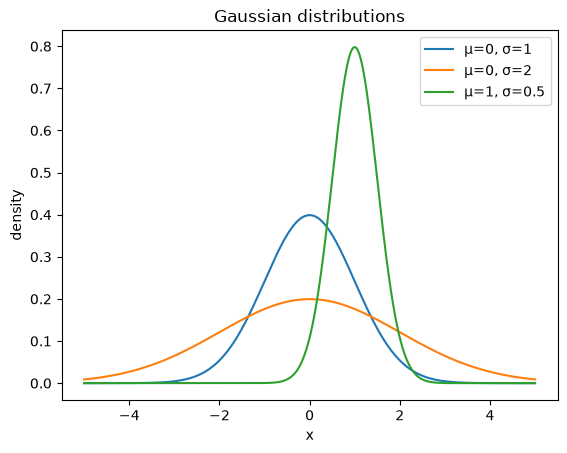

In [17]:
def gaussian_pdf(x, mu=0.0, sigma=1.0):
    x = np.asarray(x)
    return (
        1 / (np.sqrt(2*np.pi) * sigma)
        * np.exp(-0.5 * ((x - mu) / sigma)**2)
    )

x = np.linspace(-5, 5, 1000)

for mu, sigma in [(0, 1), (0, 2), (1, 0.5)]:
    plt.plot(
        x,
        gaussian_pdf(x, mu, sigma),
        label=f"μ={mu}, σ={sigma}"
    )

plt.xlabel("x")
plt.ylabel("density")
plt.title("Gaussian distributions")
plt.legend()
plt.show()

### Precision

Instead of variance, we can use the precision

$$
\beta
=
\frac{1}{\sigma^2}.
$$

Then

$$
\mathcal{N}(x;\mu,\beta^{-1})
=
\sqrt{\frac{\beta}{2\pi}}
\exp
\left(
-\frac12\beta(x-\mu)^2
\right).
$$

In [18]:
mu = 1.0
sigma = 2.0
beta = 1 / sigma**2
x0 = 2.5

via_sigma = gaussian_pdf(x0, mu, sigma)

via_beta = (
    np.sqrt(beta / (2*np.pi))
    * np.exp(-0.5 * beta * (x0 - mu)**2)
)

print(via_sigma, via_beta)
assert np.isclose(via_sigma, via_beta)

0.15056871607740221 0.15056871607740221


# 13. Multivariate Gaussian

For $X\in\mathbb{R}^n$, the multivariate Gaussian is

$$
\mathcal{N}(x;\mu,\Sigma)
=
\frac{1}
{\sqrt{(2\pi)^n\det(\Sigma)}}
\exp
\left[
-\frac12
(x-\mu)^T
\Sigma^{-1}
(x-\mu)
\right].
$$

Here:

- $\mu$ is the mean vector.
- $\Sigma$ is the covariance matrix.
- $\Sigma^{-1}$ is the precision matrix.

The matrix $\Sigma$ must be symmetric positive definite for the ordinary nonsingular Gaussian density.

In [19]:
def mvn_pdf(x, mu, Sigma):
    x = np.asarray(x)
    mu = np.asarray(mu)
    Sigma = np.asarray(Sigma)

    n = len(mu)
    delta = x - mu
    inv = np.linalg.inv(Sigma)

    norm = 1 / np.sqrt((2*np.pi)**n * np.linalg.det(Sigma))
    exponent = -0.5 * delta.T @ inv @ delta

    return norm * np.exp(exponent)

mu = np.array([0.0, 0.0])
Sigma = np.array([
    [1.0, 0.7],
    [0.7, 1.5]
])

print("density at origin:", mvn_pdf(np.zeros(2), mu, Sigma))

density at origin: 0.15836508738219027


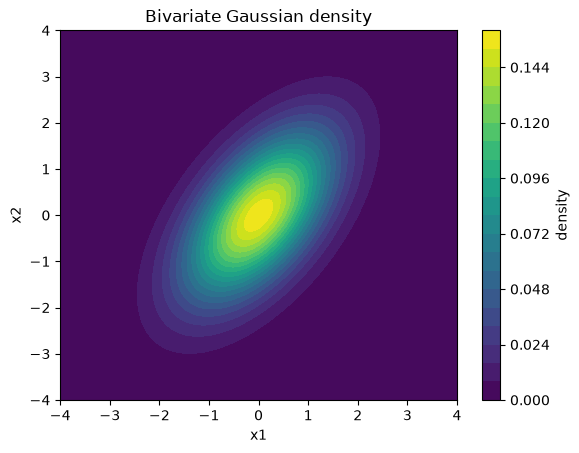

In [20]:
grid = np.linspace(-4, 4, 180)
Xg, Yg = np.meshgrid(grid, grid)
Z = np.zeros_like(Xg)

for i in range(len(grid)):
    for j in range(len(grid)):
        Z[i, j] = mvn_pdf(
            np.array([Xg[i, j], Yg[i, j]]),
            mu,
            Sigma
        )

plt.contourf(Xg, Yg, Z, levels=20)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Bivariate Gaussian density")
plt.colorbar(label="density")
plt.show()

# 14. Exponential and Laplace Distributions

For rate $\lambda>0$, the exponential distribution is

$$
p(x;\lambda)
=
\lambda
\mathbf{1}_{x\ge0}
\exp(-\lambda x).
$$

The indicator makes the density zero for negative $x$.

The Laplace distribution is

$$
\operatorname{Laplace}(x;\mu,\gamma)
=
\frac{1}{2\gamma}
\exp
\left(
-\frac{|x-\mu|}{\gamma}
\right).
$$

The Laplace distribution has a sharper peak around $\mu$ than a Gaussian with a comparable scale.

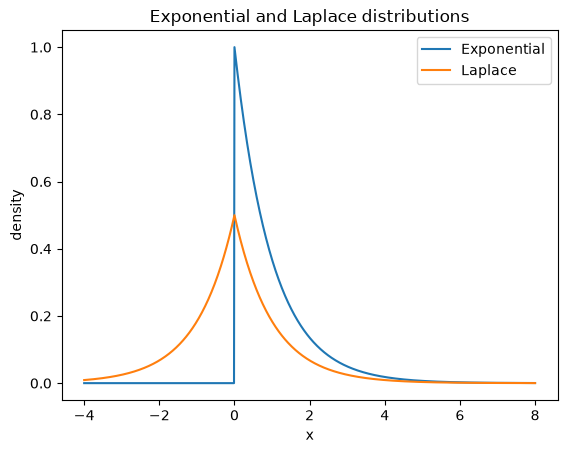

In [21]:
def exponential_pdf(x, lam=1.0):
    x = np.asarray(x)
    return np.where(x >= 0, lam * np.exp(-lam*x), 0.0)

def laplace_pdf(x, mu=0.0, gamma=1.0):
    x = np.asarray(x)
    return (
        1 / (2*gamma)
        * np.exp(-np.abs(x-mu)/gamma)
    )

x = np.linspace(-4, 8, 1000)

plt.plot(x, exponential_pdf(x), label="Exponential")
plt.plot(x, laplace_pdf(x), label="Laplace")
plt.xlabel("x")
plt.ylabel("density")
plt.title("Exponential and Laplace distributions")
plt.legend()
plt.show()

# 15. Dirac Delta and Empirical Distributions

The Dirac delta $\delta(x)$ is a generalized function concentrated at zero.

A shifted delta is written

$$
\delta(x-\mu).
$$

It places all probability mass at $\mu$.

For observations $x^{(1)},\ldots,x^{(m)}$, the empirical distribution can be written formally as

$$
\hat{p}(x)
=
\frac{1}{m}
\sum_{i=1}^{m}
\delta
\left(
x-x^{(i)}
\right).
$$

A practical visualization can approximate the delta using a very narrow Gaussian.

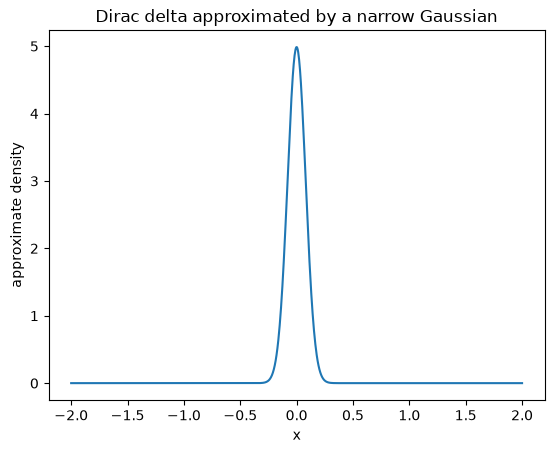

In [22]:
def delta_approx(x, mu=0.0, eps=0.05):
    return gaussian_pdf(x, mu, eps)

x = np.linspace(-2, 2, 1000)

plt.plot(x, delta_approx(x, eps=0.08))
plt.xlabel("x")
plt.ylabel("approximate density")
plt.title("Dirac delta approximated by a narrow Gaussian")
plt.show()

# 16. Mixture Distributions

A mixture distribution combines component distributions.

Let $C$ denote the component identity. Then

$$
P(x)
=
\sum_i
P(C=i)
P(x\mid C=i).
$$

The component identity is sampled first, and then $x$ is sampled from the selected component.

A Gaussian mixture is therefore

$$
p(x)
=
\sum_{i=1}^{K}
\pi_i
\mathcal{N}(x;\mu_i,\sigma_i^2),
$$

where

$$
\pi_i\ge0,
\qquad
\sum_{i=1}^{K}\pi_i=1.
$$

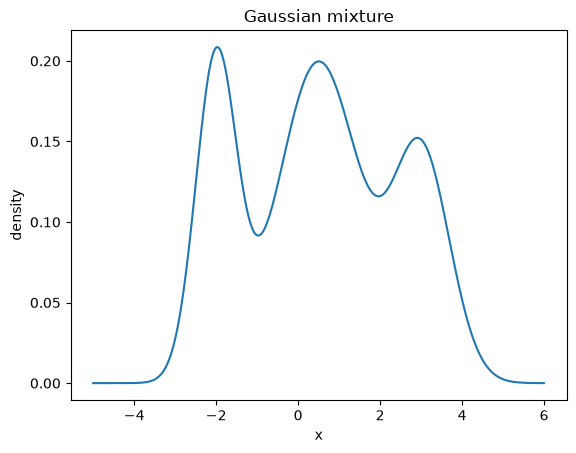

weights sum: 1.0
approximate integral: 0.9999977029401788


In [23]:
def gaussian_mixture_pdf(x, weights, mus, sigmas):
    x = np.asarray(x)
    total = np.zeros_like(x, dtype=float)

    for w, mu_i, sigma_i in zip(weights, mus, sigmas):
        total += w * gaussian_pdf(x, mu_i, sigma_i)

    return total

weights = np.array([0.25, 0.50, 0.25])
mus = np.array([-2.0, 0.5, 3.0])
sigmas = np.array([0.5, 1.0, 0.7])

x = np.linspace(-5, 6, 1000)
mixture = gaussian_mixture_pdf(
    x, weights, mus, sigmas
)

plt.plot(x, mixture)
plt.xlabel("x")
plt.ylabel("density")
plt.title("Gaussian mixture")
plt.show()

print("weights sum:", weights.sum())
print("approximate integral:", np.trapezoid(mixture, x))

# 17. Logistic Sigmoid

The logistic sigmoid is

$$
\sigma(x)
=
\frac{1}{1+\exp(-x)}.
$$

It maps real numbers into the interval $(0,1)$, which makes it useful for parameterizing a Bernoulli probability.

Its derivative is

$$
\sigma'(x)
=
\sigma(x)(1-\sigma(x)).
$$

Another useful identity is

$$
1-\sigma(x)
=
\sigma(-x).
$$

The inverse is

$$
\sigma^{-1}(p)
=
\log
\left(
\frac{p}{1-p}
\right).
$$

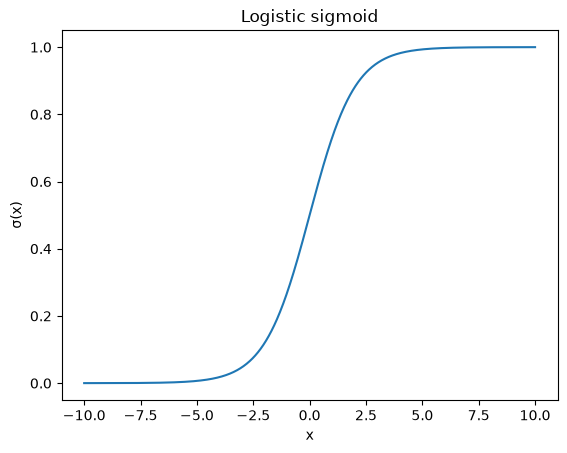

In [24]:
def sigmoid(x):
    x = np.asarray(x)

    # Numerically stable implementation.
    out = np.empty_like(x, dtype=float)
    pos = x >= 0

    out[pos] = 1 / (1 + np.exp(-x[pos]))

    exp_x = np.exp(x[~pos])
    out[~pos] = exp_x / (1 + exp_x)

    return out

x = np.linspace(-10, 10, 1000)

plt.plot(x, sigmoid(x))
plt.xlabel("x")
plt.ylabel("σ(x)")
plt.title("Logistic sigmoid")
plt.ylim(-0.05, 1.05)
plt.show()

In [25]:
x = np.linspace(-6, 6, 200)

left = 1 - sigmoid(x)
right = sigmoid(-x)

assert np.allclose(left, right)

s = sigmoid(x)

numerical_derivative = (
    sigmoid(x + 1e-5) - sigmoid(x - 1e-5)
) / (2e-5)

analytic_derivative = s * (1 - s)

print(
    "max derivative error:",
    np.max(
        np.abs(
            numerical_derivative
            - analytic_derivative
        )
    )
)

max derivative error: 1.10122410322544e-11


# 18. Softplus

The softplus function is

$$
\operatorname{softplus}(x)
=
\log(1+\exp(x)).
$$

It is a smooth approximation to the positive-part function

$$
x^+
=
\max(0,x).
$$

A particularly useful identity is

$$
\frac{d}{dx}\operatorname{softplus}(x)
=
\sigma(x).
$$

Softplus can be useful when a model needs to produce a positive parameter such as a scale.

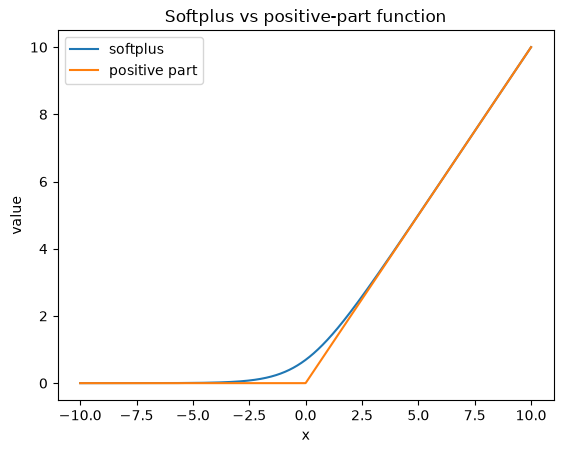

In [26]:
def softplus(x):
    x = np.asarray(x)

    # Stable implementation of log(1 + exp(x)).
    return (
        np.maximum(x, 0)
        + np.log1p(np.exp(-np.abs(x)))
    )

x = np.linspace(-10, 10, 1000)

plt.plot(x, softplus(x), label="softplus")
plt.plot(x, np.maximum(0, x), label="positive part")

plt.xlabel("x")
plt.ylabel("value")
plt.title("Softplus vs positive-part function")
plt.legend()
plt.show()

In [27]:
x = np.linspace(-8, 8, 300)

derivative = (
    softplus(x + 1e-5)
    - softplus(x - 1e-5)
) / (2e-5)

print(
    "max error in softplus'(x)=sigmoid(x):",
    np.max(np.abs(derivative - sigmoid(x)))
)

max error in softplus'(x)=sigmoid(x): 7.556899550564822e-11


# 19. Bayes' Rule

Bayes' rule reverses a conditional distribution:

$$
P(x\mid y)
=
\frac{
P(x)P(y\mid x)
}{
P(y)
}.
$$

The denominator is the evidence, obtained by marginalization:

$$
P(y)
=
\sum_x P(y\mid x)P(x)
$$

for a discrete variable $x$.

The four important pieces are:

- **Prior:** $P(x)$
- **Likelihood:** $P(y\mid x)$
- **Evidence:** $P(y)$
- **Posterior:** $P(x\mid y)$

In [28]:
# x = hidden class
# y = observed binary signal

prior = np.array([0.3, 0.7])
likelihood_y1_given_x = np.array([0.8, 0.2])

p_y1 = np.sum(
    prior * likelihood_y1_given_x
)

posterior = (
    prior
    * likelihood_y1_given_x
    / p_y1
)

print("P(y=1):", p_y1)
print("P(x | y=1):", posterior)
print("posterior sum:", posterior.sum())

assert np.isclose(posterior.sum(), 1)

P(y=1): 0.38
P(x | y=1): [0.6316 0.3684]
posterior sum: 1.0


### Bayes' rule as normalization

The numerator

$$
P(x)P(y\mid x)
$$

gives an unnormalized posterior over $x$.

Dividing by $P(y)$ makes it a proper probability distribution.

# 20. Change of Variables

Probability distributions transform when we transform the underlying random variable.

Suppose

$$
Y=g(X).
$$

For a one-dimensional monotonic transformation,

$$
p_X(x)
=
p_Y(g(x))
\left|
\frac{dg(x)}{dx}
\right|.
$$

Equivalently,

$$
p_Y(y)
=
p_X(g^{-1}(y))
\left|
\frac{d g^{-1}(y)}{dy}
\right|.
$$

In multiple dimensions, the derivative becomes the **Jacobian matrix**, and the scaling factor is the absolute determinant of that Jacobian.

### Example: $Y=2X$

Suppose

$$
X\sim U(0,1)
$$

and

$$
Y=2X.
$$

Then $Y$ lies on $[0,2]$.

Since

$$
\frac{dy}{dx}=2,
$$

the transformed density is

$$
p_Y(y)
=
\frac12,
\qquad
0\le y\le2.
$$

The Jacobian accounts for the fact that the transformation stretches the interval by a factor of $2$.

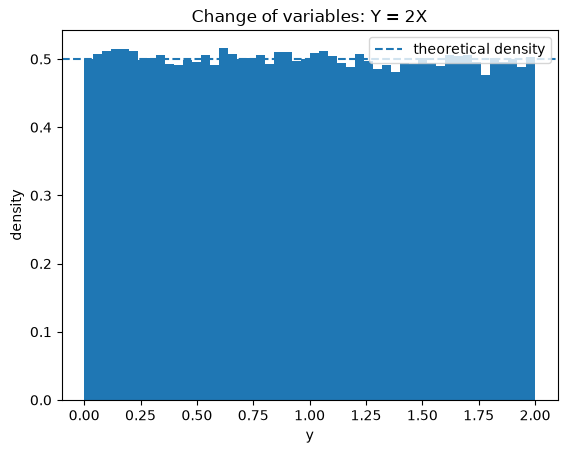

In [29]:
n = 100_000

X = rng.uniform(0, 1, size=n)
Y = 2 * X

plt.hist(Y, bins=50, density=True)
plt.axhline(
    0.5,
    linestyle="--",
    label="theoretical density"
)

plt.xlabel("y")
plt.ylabel("density")
plt.title("Change of variables: Y = 2X")
plt.legend()
plt.show()

# 21. Self-Information

Information theory begins with the idea that unlikely events should convey more information than likely events.

The self-information of an event with probability $P(x)$ is

$$
I(x)
=
-\log P(x).
$$

For independent events,

$$
I(x,y)
=
I(x)+I(y),
$$

because

$$
-\log(P(x)P(y))
=
-\log P(x)-\log P(y).
$$

With natural logarithms, information is measured in **nats**. With base-$2$ logarithms, it is measured in **bits**.

In [30]:
probabilities = np.array([
    0.9,
    0.5,
    0.1,
    0.01
])

information_nats = -np.log(probabilities)
information_bits = -np.log2(probabilities)

for p_i, i_n, i_b in zip(
    probabilities,
    information_nats,
    information_bits
):
    print(
        f"P={p_i:>4}: "
        f"{i_n:.3f} nats, "
        f"{i_b:.3f} bits"
    )

P= 0.9: 0.105 nats, 0.152 bits
P= 0.5: 0.693 nats, 1.000 bits
P= 0.1: 2.303 nats, 3.322 bits
P=0.01: 4.605 nats, 6.644 bits


# 22. Shannon Entropy

Entropy is the expected self-information:

$$
H(X)
=
\mathbb{E}_{X\sim P}[I(X)].
$$

Therefore,

$$
H(X)
=
-\mathbb{E}_{X\sim P}
[\log P(X)].
$$

For a discrete distribution,

$$
H(P)
=
-\sum_x P(x)\log P(x).
$$

Entropy is low for nearly deterministic distributions and high for distributions that spread probability more evenly across their states.

In [31]:
def entropy(p, base=np.e):
    p = np.asarray(p, dtype=float)
    p = p[p > 0]

    h = -np.sum(p * np.log(p))

    return h / np.log(base)

p = np.array([0.5, 0.5])
p2 = np.array([0.99, 0.01])

print("fair coin entropy:",
      entropy(p),
      "nats")

print("nearly deterministic entropy:",
      entropy(p2),
      "nats")

fair coin entropy: 0.6931471805599453 nats
nearly deterministic entropy: 0.056001534354847345 nats


### Entropy of a Bernoulli variable

For $X\sim\operatorname{Bernoulli}(\phi)$,

$$
H(X)
=
-\phi\log\phi
-
(1-\phi)\log(1-\phi).
$$

The maximum occurs at $\phi=\frac12$.

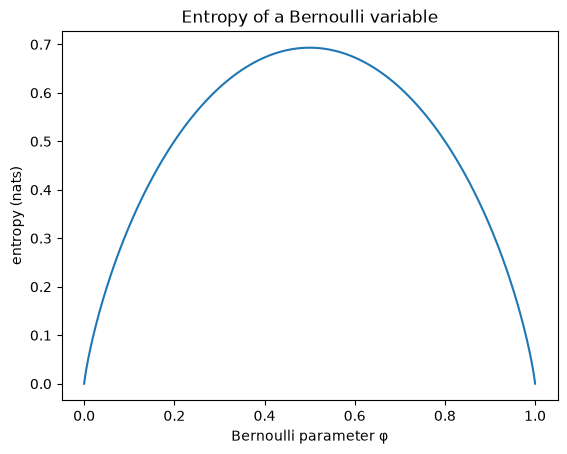

Approximate maximizing φ: 0.4994995005005004
log(2): 0.6931471805599453


In [32]:
phi = np.linspace(1e-6, 1-1e-6, 1000)

H = (
    -phi * np.log(phi)
    - (1-phi) * np.log(1-phi)
)

plt.plot(phi, H)
plt.xlabel("Bernoulli parameter φ")
plt.ylabel("entropy (nats)")
plt.title("Entropy of a Bernoulli variable")
plt.show()

phi_max = phi[np.argmax(H)]

print("Approximate maximizing φ:", phi_max)
print("log(2):", np.log(2))

# 23. KL Divergence

For distributions $P$ and $Q$ over the same variable,

$$
D_{\mathrm{KL}}(P\|Q)
=
\mathbb{E}_{X\sim P}
\left[
\log
\frac{P(X)}{Q(X)}
\right].
$$

For a discrete distribution,

$$
D_{\mathrm{KL}}(P\|Q)
=
\sum_x
P(x)
\left[
\log P(x)-\log Q(x)
\right].
$$

Important properties:

$$
D_{\mathrm{KL}}(P\|Q)\ge0
$$

and

$$
D_{\mathrm{KL}}(P\|Q)=0
$$

when the distributions agree, up to the usual almost-everywhere qualification.

However,

$$
D_{\mathrm{KL}}(P\|Q)
\ne
D_{\mathrm{KL}}(Q\|P)
$$

in general.

Therefore KL divergence is not a true metric.

In [33]:
def kl_divergence(p, q):
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)

    mask = p > 0

    return np.sum(
        p[mask]
        * np.log(p[mask] / q[mask])
    )

P = np.array([0.7, 0.2, 0.1])
Q = np.array([0.5, 0.3, 0.2])

print("KL(P || Q):", kl_divergence(P, Q))
print("KL(Q || P):", kl_divergence(Q, P))

KL(P || Q): 0.0851228259572216
KL(Q || P): 0.09203285023383187


### Cross-entropy connection

Cross-entropy is

$$
H(P,Q)
=
-\mathbb{E}_{X\sim P}
[\log Q(X)].
$$

The relationship between cross-entropy, entropy, and KL divergence is

$$
D_{\mathrm{KL}}(P\|Q)
=
H(P,Q)-H(P).
$$

This is one reason cross-entropy losses appear so frequently in machine learning.

In [34]:
def cross_entropy(p, q):
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)

    mask = p > 0

    return -np.sum(
        p[mask] * np.log(q[mask])
    )

lhs = kl_divergence(P, Q)
rhs = cross_entropy(P, Q) - entropy(P)

print("KL:", lhs)
print("Cross entropy - entropy:", rhs)

assert np.isclose(lhs, rhs)

KL: 0.0851228259572216
Cross entropy - entropy: 0.08512282595722176


### Why KL direction matters

The direction of KL divergence can change the behavior of an approximation.

For example, if a multimodal distribution $P$ is approximated by a simpler distribution $Q$, minimizing

$$
D_{\mathrm{KL}}(P\|Q)
$$

and minimizing

$$
D_{\mathrm{KL}}(Q\|P)
$$

can produce qualitatively different approximations.

The asymmetry is therefore not a technical curiosity; it changes optimization behavior.

# 24. Directed Graphical Models

A graphical model represents a factorization of a probability distribution.

In a directed acyclic graph, each node corresponds to a random variable and its conditional distribution depends on its parents.

For example, a five-variable factorization can have the form

$$
p(a,b,c,d,e)
=
p(a)
p(b\mid a)
p(c\mid a,b)
p(d\mid b)
p(e\mid c).
$$

Graphical structure therefore gives a compact representation of conditional relationships in the joint distribution.

In [35]:
# A toy binary directed model.

def p_a(a):
    return 0.6 if a == 0 else 0.4

def p_b_given_a(b, a):
    probs = {
        0: {0: 0.7, 1: 0.3},
        1: {0: 0.2, 1: 0.8}
    }
    return probs[a][b]

def p_c_given_ab(c, a, b):
    probs = {
        (0, 0): {0: 0.9, 1: 0.1},
        (0, 1): {0: 0.4, 1: 0.6},
        (1, 0): {0: 0.5, 1: 0.5},
        (1, 1): {0: 0.1, 1: 0.9}
    }
    return probs[(a, b)][c]

def p_d_given_b(d, b):
    probs = {
        0: {0: 0.8, 1: 0.2},
        1: {0: 0.3, 1: 0.7}
    }
    return probs[b][d]

def p_e_given_c(e, c):
    probs = {
        0: {0: 0.6, 1: 0.4},
        1: {0: 0.1, 1: 0.9}
    }
    return probs[c][e]

total = 0

for a in [0, 1]:
    for b in [0, 1]:
        for c in [0, 1]:
            for d in [0, 1]:
                for e in [0, 1]:

                    total += (
                        p_a(a)
                        * p_b_given_a(b, a)
                        * p_c_given_ab(c, a, b)
                        * p_d_given_b(d, b)
                        * p_e_given_c(e, c)
                    )

print("Total probability:", total)

assert np.isclose(total, 1)

Total probability: 1.0


# 25. Undirected Graphical Models

For an undirected graphical model, nonnegative factors are associated with cliques.

The distribution has the form

$$
p(x)
=
\frac{1}{Z}
\prod_i
\phi^{(i)}
\left(
C^{(i)}
\right),
$$

where $Z$ is the partition function:

$$
Z
=
\sum_x
\prod_i
\phi^{(i)}
\left(
C^{(i)}
\right)
$$

for discrete variables.

The factors $\phi^{(i)}$ are **not required to be probability distributions**. They only need to be nonnegative. The partition function performs the normalization.

In [36]:
# Tiny undirected model over two binary variables.

phi = np.array([
    [1.0, 2.0],
    [3.0, 4.0]
])

Z = phi.sum()
p = phi / Z

print("Partition function Z =", Z)
print("Normalized distribution:\n", p)
print("sum =", p.sum())

assert np.isclose(p.sum(), 1)

Partition function Z = 10.0
Normalized distribution:
 [[0.1 0.2]
 [0.3 0.4]]
sum = 1.0


### Directed vs undirected

Directed versus undirected is a property of the **representation/factorization**.

A probability distribution can often be represented in more than one mathematically valid way. The graph tells us how the chosen representation factors the distribution.

# 26. Integrated Worked Example

Let's combine several concepts.

We will:

1. Define a categorical distribution.
2. Compute an expectation.
3. Compute variance.
4. Compute entropy.
5. Compare it with another distribution using KL divergence.
6. Estimate the expectation and variance using Monte Carlo sampling.

In [37]:
p = np.array([0.05, 0.15, 0.30, 0.50])
values = np.array([0., 1., 2., 3.])

mu = np.sum(p * values)
var = np.sum(
    p * (values - mu)**2
)

H = entropy(p)

q = np.array([0.10, 0.20, 0.25, 0.45])
KL = kl_divergence(p, q)

print(f"E[X]       = {mu:.4f}")
print(f"Var(X)     = {var:.4f}")
print(f"H(X)       = {H:.4f} nats")
print(f"KL(P || Q) = {KL:.4f} nats")

E[X]       = 2.2500
Var(X)     = 0.7875
H(X)       = 1.1421 nats
KL(P || Q) = 0.0296 nats


In [38]:
n = 300_000

sampled = rng.choice(
    values,
    size=n,
    p=p
)

mu_hat = sampled.mean()
var_hat = sampled.var()

print("Monte Carlo E[X]:", mu_hat)
print("Exact E[X]:      ", mu)

print("Monte Carlo Var: ", var_hat)
print("Exact Var:       ", var)

assert abs(mu_hat - mu) < 0.02
assert abs(var_hat - var) < 0.05

Monte Carlo E[X]: 2.2513733333333334
Exact E[X]:       2.25
Monte Carlo Var:  0.7867447806222221
Exact Var:        0.7875


# 27. Exercises

### Exercise A — Marginalization

Given

$$
P(X,Y)
=
\begin{pmatrix}
0.1 & 0.2 & 0.1\\
0.2 & 0.1 & 0.3
\end{pmatrix},
$$

compute $P(X)$ and $P(Y)$.

### Exercise B — Conditional probability

Using the same table, compute

$$
P(Y\mid X=1).
$$

### Exercise C — Independence

Construct the joint distribution from

$$
P(X)
=
[0.25,0.75]
$$

and

$$
P(Y)
=
[0.6,0.4].
$$

Verify that

$$
P(X,Y)=P(X)P(Y).
$$

### Exercise D — Bernoulli

For $\phi=0.2$, compute the mean and variance.

### Exercise E — Gaussian

For $\mu=3$ and $\sigma=2$, evaluate the density at $x=4$.

### Exercise F — Entropy

Which distribution has greater entropy?

$$
[0.5,0.5]
$$

or

$$
[0.9,0.1]?
$$

Explain before running the code.

### Exercise G — KL divergence

Compute both

$$
D_{\mathrm{KL}}(P\|Q)
$$

and

$$
D_{\mathrm{KL}}(Q\|P)
$$

for

$$
P=[0.8,0.2],
\qquad
Q=[0.5,0.5].
$$

What does the difference demonstrate?

In [39]:
# Exercise A / B

joint_ex = np.array([
    [0.1, 0.2, 0.1],
    [0.2, 0.1, 0.3]
])

px = joint_ex.sum(axis=1)
py = joint_ex.sum(axis=0)

py_given_x1 = (
    joint_ex[1] / px[1]
)

print("P(X):", px)
print("P(Y):", py)
print("P(Y | X=1):", py_given_x1)


# Exercise C

px_c = np.array([0.25, 0.75])
py_c = np.array([0.6, 0.4])

joint_c = np.outer(px_c, py_c)

print("\nExercise C joint:\n", joint_c)


# Exercise D

phi = 0.2

print("\nExercise D mean:", phi)
print(
    "Exercise D variance:",
    phi * (1 - phi)
)


# Exercise E

print(
    "\nExercise E:",
    gaussian_pdf(4, mu=3, sigma=2)
)


# Exercise F

print(
    "\nExercise F entropies:",
    entropy(np.array([0.5, 0.5])),
    entropy(np.array([0.9, 0.1]))
)


# Exercise G

P = np.array([0.8, 0.2])
Q = np.array([0.5, 0.5])

print(
    "\nExercise G KL(P || Q):",
    kl_divergence(P, Q)
)

print(
    "Exercise G KL(Q || P):",
    kl_divergence(Q, P)
)

P(X): [0.4 0.6]
P(Y): [0.3 0.3 0.4]
P(Y | X=1): [0.3333 0.1667 0.5   ]

Exercise C joint:
 [[0.15 0.1 ]
 [0.45 0.3 ]]

Exercise D mean: 0.2
Exercise D variance: 0.16000000000000003

Exercise E: 0.17603266338214976

Exercise F entropies: 0.6931471805599453 0.3250829733914482

Exercise G KL(P || Q): 0.19274475702175753
Exercise G KL(Q || P): 0.22314355131420976


# 28. Conceptual Checkpoint

You should now be able to explain, without looking at the formulas:

1. Why a PDF can exceed $1$ while a PMF cannot.
2. Why marginalization uses a sum for discrete variables and an integral for continuous variables.
3. The difference between $P(Y\mid X)$ and $P(X,Y)$.
4. How the chain rule decomposes a joint distribution.
5. The difference between independence and conditional independence.
6. Why zero covariance does not imply independence.
7. What the covariance matrix contains.
8. What each parameter of a Gaussian means.
9. Why precision is the inverse of variance.
10. What a mixture distribution is.
11. Why sigmoid is useful for Bernoulli parameters.
12. Why softplus can parameterize a positive quantity.
13. How Bayes' rule connects prior, likelihood, evidence, and posterior.
14. Why a Jacobian determinant appears in change of variables.
15. Why unlikely events carry more self-information.
16. Why entropy measures average uncertainty.
17. Why KL divergence is nonnegative but not symmetric.
18. What a directed graphical-model factorization means.
19. What the partition function $Z$ does in an undirected model.

# 29. Final Synthesis

The chapter can be compressed into a small set of operations.

### Represent

Use PMFs/PDFs to represent uncertainty.

### Marginalize

$$
P(x)=\sum_y P(x,y)
$$

or integrate in the continuous case.

### Condition

$$
P(y\mid x)
=
\frac{P(x,y)}{P(x)}.
$$

### Factorize

$$
P(x_1,\ldots,x_n)
=
\prod_i
P(x_i\mid x_{<i}).
$$

### Measure

$$
\mathbb{E}[f(X)],
\qquad
\operatorname{Var}(X),
\qquad
\operatorname{Cov}(X,Y).
$$

### Transform

Use sigmoid, softplus, and change-of-variables/Jacobian transformations.

### Compare

Use entropy and KL divergence to quantify uncertainty and mismatch between distributions.

### Structure

Use graphical models to represent conditional relationships and factorization.

These ideas recur throughout machine learning: probabilistic prediction, likelihoods, cross-entropy losses, latent-variable models, Bayesian inference, and generative models all build on this vocabulary.

## Source

Based on the uploaded lecture-slide PDF:

**Probability and Information Theory — Lecture slides for Chapter 3 of *Deep Learning***  
Ian Goodfellow — 2016-09-26.

The notebook is a teaching/implementation companion rather than a verbatim transcription of the slides. It adds explanations, derivations, NumPy implementations, visualizations, numerical checks, and exercises.